# Module 8 — Backtest Evaluation Report

ML-driven **Black-Litterman portfolio** vs **S&P 500 buy & hold**.

This notebook **loads the artifacts already produced by `run.py`** — it does **not** re-run the
backtest. It reads from `output/`:

| File | Contents |
|---|---|
| `backtest_results/realized_returns.parquet` | per-period return, tx cost, cumulative value |
| `backtest_results/universe_history.parquet` | the 22 tickers held at each rebalance |
| `backtest_results/weights_history.parquet` | `w*` per ticker per rebalance |
| `backtest_results/turnover_log.csv` | universe turnover per rebalance |
| `portfolios/{date}.npz` + `{date}_frontier.parquet` | Max-Sharpe weights + efficient frontier |
| `bl_outputs/{date}.npz` | μ_BL, Σ for the frontier's Max-Sharpe marker |

Plotting and metrics reuse the functions in `src/evaluation.py` (Module 8) — nothing is
reimplemented here. If a file is missing, run `python run.py` (or `--quick`/`--full`) first.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make `import src...` work whether the notebook is launched from notebooks/ or the project root.
_here = os.getcwd()
ROOT = os.path.abspath(os.path.join(_here, "..")) if os.path.basename(_here) == "notebooks" else _here
if not os.path.isdir(os.path.join(ROOT, "src")):
    ROOT = os.path.abspath(os.path.join(_here, ".."))
sys.path.insert(0, ROOT)

from src import constants as C          # noqa: E402
from src import evaluation as ev        # noqa: E402
from src import data_pipeline as dp     # noqa: E402
from src import backtest as bt          # noqa: E402

BT = C.BACKTEST_DIR
results = pd.read_parquet(os.path.join(BT, "realized_returns.parquet"))
results["date"] = pd.to_datetime(results["date"])
if "period_end" in results.columns:
    results["period_end"] = pd.to_datetime(results["period_end"])
turnover = pd.read_csv(os.path.join(BT, "turnover_log.csv"))

# risk-free rate (FRED DTB3, falls back to 0% offline) — same source the report used
rf_annual = bt.get_risk_free_rate()

print(f"Loaded {len(results)} rebalance periods: "
      f"{results['date'].min().date()} -> {results['date'].max().date()};  rf = {rf_annual:.2%}")
results

Loaded 2 rebalance periods: 2020-01-02 -> 2020-04-01;  rf = 3.74%


,date,period_end,period_return,transaction_cost,portfolio_value
0,2020-01-02,2020-04-01,-0.190977,0.001000,0.808214
1,2020-04-01,2020-07-01,0.335997,0.001916,1.077703


## 1. Cumulative return — BL strategy vs S&P 500 (buy & hold)

Both lines are on the same axis and the **same holding intervals** (the benchmark is computed over
each `(date, period_end)` pair the strategy actually held), so the comparison is apples-to-apples.

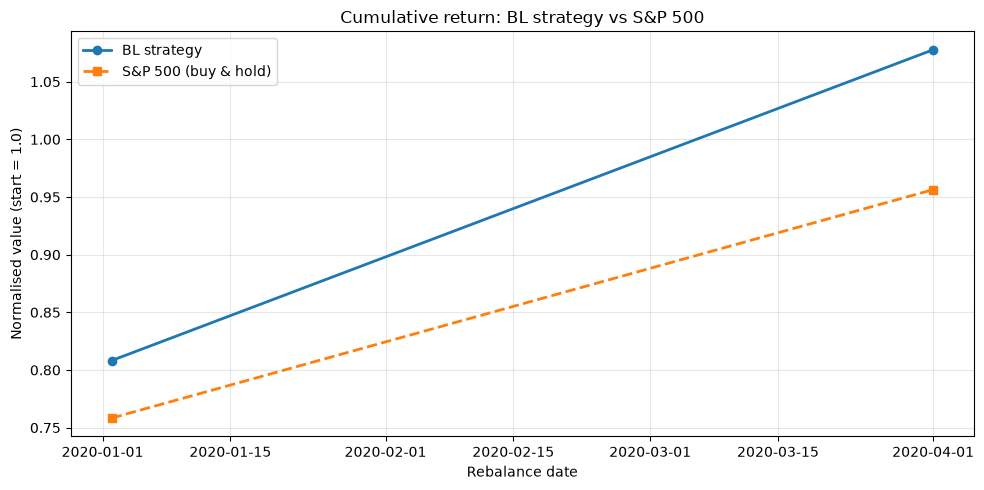

In [2]:
# benchmark over the strategy's exact holding intervals (08 §3)
if "period_end" in results.columns:
    periods = list(zip(results["date"], results["period_end"]))
else:
    bounds = list(results["date"]) + [pd.Timestamp(C.BACKTEST_END)]
    periods = list(zip(bounds[:-1], bounds[1:]))

bench = ev.benchmark_series(periods)          # S&P 500 buy & hold, same intervals

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(results["date"], results["portfolio_value"], marker="o", lw=2, label="BL strategy")
if not bench.empty:
    bench_pv = (1 + bench).cumprod()
    ax.plot(bench_pv.index, bench_pv.values, marker="s", lw=2, ls="--", label="S&P 500 (buy & hold)")
ax.set_title("Cumulative return: BL strategy vs S&P 500")
ax.set_ylabel("Normalised value (start = 1.0)")
ax.set_xlabel("Rebalance date")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Performance metrics — strategy vs benchmark

Computed by `evaluation.metric_table` on the realised quarterly returns
(`periods_per_year = 4`, 08 §2): annualised return & volatility, Sharpe, max drawdown,
Calmar, and VaR/CVaR at 95%.

In [3]:
r = results.set_index("date")["period_return"]
pv = results.set_index("date")["portfolio_value"]

strat = ev.metric_table(r, pv, rf_annual)
if not bench.empty:
    bench_tbl = ev.metric_table(bench, (1 + bench).cumprod(), rf_annual)
else:
    bench_tbl = {k: np.nan for k in strat}

comp = pd.DataFrame({"Strategy": strat, "S&P 500 (B&H)": bench_tbl})

def _fmt_row(name, v):
    if pd.isna(v):
        return "n/a"
    return f"{v:.3f}" if "Ratio" in name else f"{v:.2%}"

# build a string (object) table directly — pandas 3.0 won't coerce a float64
# frame to hold formatted strings in place
comp_fmt = pd.DataFrame(
    {col: {name: _fmt_row(name, comp.loc[name, col]) for name in comp.index}
     for col in comp.columns}
)
comp_fmt

,Strategy,S&P 500 (B&H)
Annualized Return,16.82%,-8.53%
Annualized Volatility,74.53%,71.12%
Sharpe Ratio,0.339,0.002
Max Drawdown,0.00%,0.00%
Calmar Ratio,n/a,n/a
VaR (95%),-16.46%,-21.65%
CVaR (95%),-19.10%,-24.17%


## 3. Efficient frontier at representative rebalance dates

For up to three dates (first / middle / last available), the min-variance frontier traced in
Module 6, with the **Max-Sharpe** portfolio actually held marked as a red star.

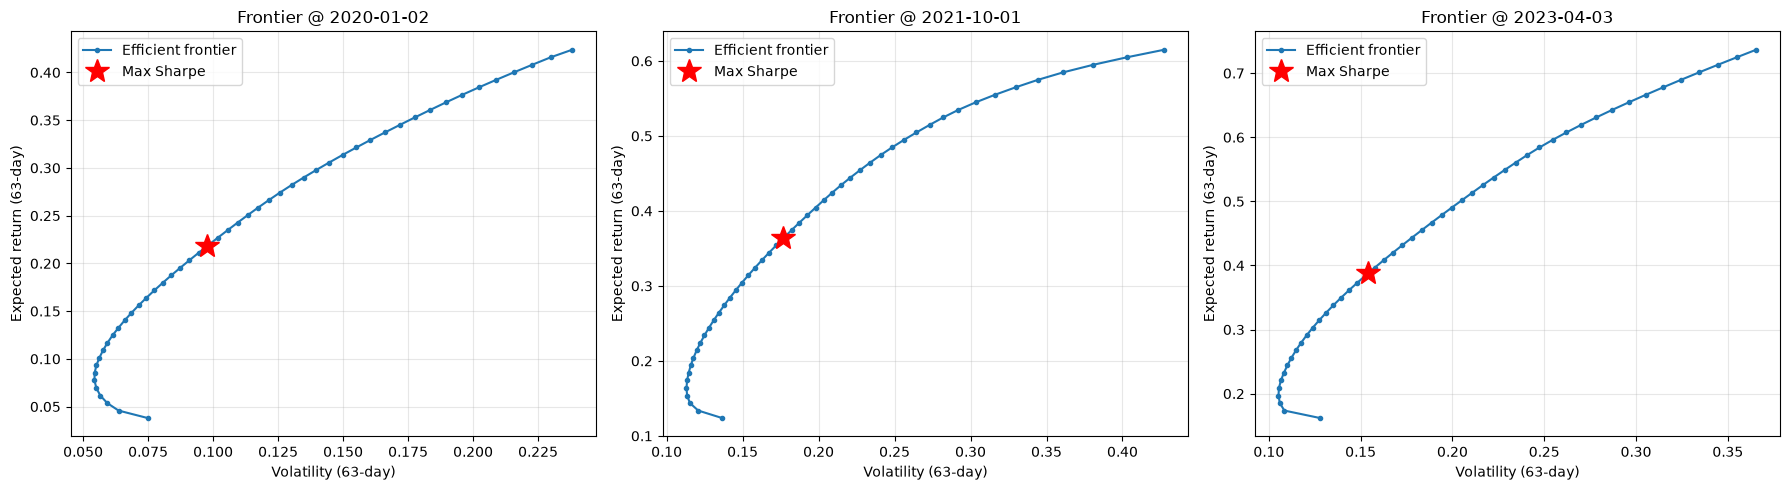

In [4]:
frontier_files = sorted(
    f[:-len("_frontier.parquet")] for f in os.listdir(C.PORTFOLIO_DIR)
    if f.endswith("_frontier.parquet")
) if os.path.isdir(C.PORTFOLIO_DIR) else []

if not frontier_files:
    print("No frontier files in output/portfolios/ — run run.py first.")
else:
    pick = sorted(set([frontier_files[0],
                       frontier_files[len(frontier_files) // 2],
                       frontier_files[-1]]))
    fig, axes = plt.subplots(1, len(pick), figsize=(6 * len(pick), 5), squeeze=False)
    for ax, d in zip(axes[0], pick):
        fr = pd.read_parquet(os.path.join(C.PORTFOLIO_DIR, f"{d}_frontier.parquet"))
        ax.plot(fr["volatility"], fr["target_return"], "-o", ms=3, label="Efficient frontier")
        pnpz = os.path.join(C.PORTFOLIO_DIR, f"{d}.npz")
        bnpz = os.path.join(C.BL_DIR, f"{d}.npz")
        if os.path.exists(pnpz) and os.path.exists(bnpz):
            z = np.load(pnpz, allow_pickle=True)
            b = np.load(bnpz)
            w = z["w_star"]
            ax.plot(np.sqrt(w @ b["Sigma"] @ w), w @ b["mu_BL"], "r*", ms=18, label="Max Sharpe")
        ax.set_title(f"Frontier @ {d}")
        ax.set_xlabel("Volatility (63-day)")
        ax.set_ylabel("Expected return (63-day)")
        ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 4. Universe turnover over time

Percentage of the 22-stock universe that changed at each rebalance (`1 − overlap_pct` from
`turnover_log.csv`), plus the cumulative transaction-cost drag.

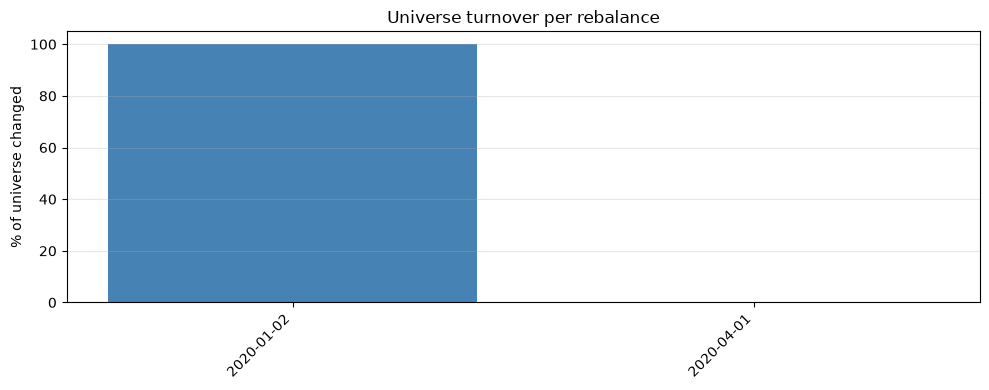

Total transaction cost paid over the backtest: 0.29% of portfolio value (cumulative drag).


In [5]:
if turnover.empty:
    print("turnover_log.csv is empty.")
else:
    changed = (1 - turnover["overlap_pct"].fillna(0)) * 100
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(range(len(turnover)), changed, color="steelblue")
    ax.set_xticks(range(len(turnover)))
    ax.set_xticklabels(turnover["date"].astype(str).str[:10], rotation=45, ha="right")
    ax.set_ylabel("% of universe changed")
    ax.set_title("Universe turnover per rebalance")
    ax.grid(alpha=0.3, axis="y")
    plt.tight_layout(); plt.show()
    print(f"Total transaction cost paid over the backtest: "
          f"{results['transaction_cost'].sum():.2%} of portfolio value (cumulative drag).")

## 5. ML quality diagnostics (bonus)

Independent of portfolio performance: does the LSTM→SVR actually predict? `evaluation.ml_diagnostics`
computes the Information Coefficient (rank correlation of predicted vs realised 63-day returns) and
directional accuracy across the cached prediction files. IC > 0.05 is weakly predictive, > 0.1 is
good for cross-sectional equity (08 §4.1); 50% directional accuracy is the random baseline.

In [6]:
sector_map = dp.load_sector_map()
diag = ev.ml_diagnostics(sector_map)
print(f"Mean Information Coefficient : {diag['mean_ic']:.4f}")
print(f"Mean directional accuracy    : {diag['mean_directional_accuracy']:.2%}")
ic_by_sector = diag["ic_by_sector"]
ic_by_sector if isinstance(ic_by_sector, pd.DataFrame) and not ic_by_sector.empty else "no per-sector IC yet"

Mean Information Coefficient : 0.0299
Mean directional accuracy    : 56.87%


,sector,ic
0,Communication Services,0.021459
1,Consumer Discretionary,0.051405
2,Consumer Staples,-0.007886
3,Energy,0.025070
4,Financials,-0.054172
5,Health Care,0.001426
6,Industrials,-0.008518
7,Information Technology,0.021276
8,Materials,-0.097260
9,Real Estate,0.094847
